# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 6: GOM CỤM DỮ LIỆU CHỮ SỐ VIẾT TAY MNIST BẰNG K-MEANS
### (PHÂN CỤM KHÔNG GIÁM SÁT, ÁNH XẠ NHÃN ĐA SỐ, ĐÁNH GIÁ VÀ TRỰC QUAN HÓA TÂM CỤM)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import keras

print("Đã tải đầy đủ các thư viện cần thiết cho Bài 6.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


I0000 00:00:1794280629.646304   99322 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Đã tải đầy đủ các thư viện cần thiết cho Bài 6.


I0000 00:00:1794280630.843804   99322 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Câu a: Đọc dữ liệu MNIST, làm phẳng ma trận thành vector 784 chiều và chuẩn hóa về đoạn [0, 1]
Hướng dẫn: Sử dụng `keras.datasets.mnist.load_data()`, chuyển mảng ảnh từ $28 \times 28$ thành vector 784 chiều và chia cho 255.0.

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

# Gom toàn bộ dữ liệu 70,000 ảnh để thực hiện gom cụm toàn diện
X_all = np.concatenate([train_images, test_images], axis=0)
y_all = np.concatenate([train_labels, test_labels], axis=0)

# Làm phẳng ma trận 28x28 thành vector 784 chiều và chuẩn hóa về [0, 1]
X_flat = X_all.reshape(-1, 784).astype("float32") / 255.0

print("Đã nạp và tiền xử lý dữ liệu MNIST thành công.")
print(f"Tổng số mẫu ảnh: {X_flat.shape[0]}")
print(f"Số chiều thuộc tính mỗi ảnh: {X_flat.shape[1]}")
print(f"Khoảng giá trị pixel sau chuẩn hóa: [{X_flat.min():.1f}, {X_flat.max():.1f}]")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã nạp và tiền xử lý dữ liệu MNIST thành công.
Tổng số mẫu ảnh: 70000
Số chiều thuộc tính mỗi ảnh: 784
Khoảng giá trị pixel sau chuẩn hóa: [0.0, 1.0]


### Câu b: Áp dụng thuật toán K-Means để gom dữ liệu thành 10 cụm
Hướng dẫn: Sử dụng `KMeans(n_clusters=10, random_state=42)` trên ma trận dữ liệu ảnh đã làm phẳng.

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

kmeans_mnist = KMeans(n_clusters=10, init='k-means++', n_init=10, max_iter=300, random_state=42)
cluster_labels = kmeans_mnist.fit_predict(X_flat)

print("Đã hoàn tất quá trình gom cụm bằng K-Means với 10 cụm.")
print(f"Tổng bình phương khoảng cách trong cụm (Inertia): {kmeans_mnist.inertia_:.2f}")
print(f"Số lượng tâm cụm: {kmeans_mnist.cluster_centers_.shape[0]}, mỗi tâm có kích thước {kmeans_mnist.cluster_centers_.shape[1]} chiều.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Đã hoàn tất quá trình gom cụm bằng K-Means với 10 cụm.
Tổng bình phương khoảng cách trong cụm (Inertia): 2744059.25
Số lượng tâm cụm: 10, mỗi tâm có kích thước 784 chiều.


### Câu c: Thiết lập ánh xạ từ số cụm (Cluster ID) sang nhãn chữ số thực tế (Majority Voting)
Hướng dẫn: Với mỗi cụm từ 0 đến 9, tìm nhãn thực tế xuất hiện nhiều nhất (Mode) trong cụm đó để gán làm chữ số đại diện cho cụm.

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

cluster_to_digit = {}
print("Bảng ánh xạ cụm sang nhãn chữ số thực tế (Majority Voting):")
print("-" * 65)
print(f"{'Cụm (Cluster)':^15} | {'Số mẫu':^10} | {'Chữ số chiếm đa số':^20} | {'Tỷ lệ áp đảo':^12}")
print("-" * 65)

for c in range(10):
    mask = (cluster_labels == c)
    labels_in_cluster = y_all[mask]
    counts = np.bincount(labels_in_cluster, minlength=10)
    majority_digit = int(np.argmax(counts))
    majority_count = counts[majority_digit]
    total_in_cluster = len(labels_in_cluster)
    ratio = majority_count / total_in_cluster * 100

    cluster_to_digit[c] = majority_digit
    print(f"{c:^15d} | {total_in_cluster:^10d} | {majority_digit:^20d} | {ratio:^10.2f} %")

print("-" * 65)
print(f"Từ điển ánh xạ (Cluster -> Digit): {cluster_to_digit}")

# Chuyển đổi nhãn cụm sang nhãn dự đoán chữ số
y_pred_digits = np.array([cluster_to_digit[c] for c in cluster_labels])

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bảng ánh xạ cụm sang nhãn chữ số thực tế (Majority Voting):
-----------------------------------------------------------------
 Cụm (Cluster)  |   Số mẫu   |  Chữ số chiếm đa số  | Tỷ lệ áp đảo
-----------------------------------------------------------------
       0        |    6419    |          6           |   29.99    %
       1        |   10431    |          4           |   35.82    %
       2        |    6713    |          1           |   63.95    %
       3        |    5277    |          1           |   66.84    %
       4        |    5120    |          6           |   86.76    %
       5        |    8633    |          3           |   53.17    %
       6        |    5370    |          0           |   93.85    %
       7        |    9996    |          7           |   44.07    %
       8        |    6732    |          8           |   61.23    %
       9        |    5309    |          2           |   91.62    %
---------------------------

### Câu d: Đánh giá độ phù hợp của kết quả gom cụm so với nhãn thực tế
Hướng dẫn: So sánh nhãn dự đoán sau khi ánh xạ với nhãn thực tế `y_all`: tính Accuracy, Precision, Recall, F1-score và hiển thị ma trận nhầm lẫn (Confusion Matrix).

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Độ chính xác tương đồng (Clustering Accuracy): 0.5849 (58.49%)

Báo cáo chi tiết các độ đo đánh giá phân lớp (Classification Report):
              precision    recall  f1-score   support

    Chữ số 0     0.9385    0.7301    0.8213      6903
    Chữ số 1     0.6522    0.9928    0.7872      7877
    Chữ số 2     0.9162    0.6959    0.7910      6990
    Chữ số 3     0.5317    0.6428    0.5820      7141
    Chữ số 4     0.3582    0.5475    0.4330      6824
    Chữ số 5     0.0000    0.0000    0.0000      6313
    Chữ số 6     0.5518    0.9260    0.6915      6876
    Chữ số 7     0.4407    0.6040    0.5096      7293
    Chữ số 8     0.6123    0.6040    0.6081      6825
    Chữ số 9     0.0000    0.0000    0.0000      6958

    accuracy                         0.5849     70000
   macro avg     0.5002    0.5743    0.5224     70000
weighted avg     0.5064    0.5849    0.5305     70000



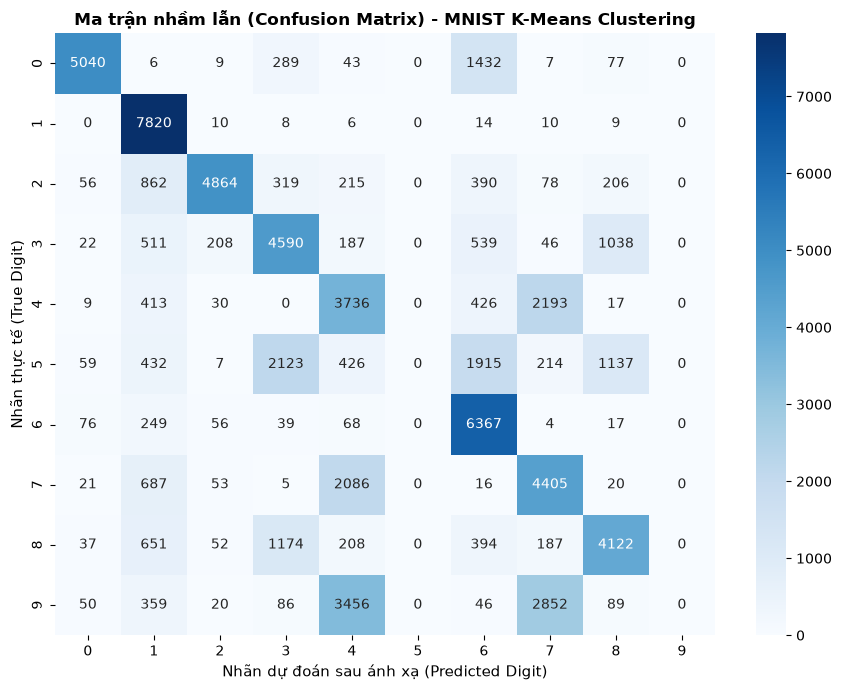

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

acc = accuracy_score(y_all, y_pred_digits)
print(f"Độ chính xác tương đồng (Clustering Accuracy): {acc:.4f} ({acc * 100:.2f}%)")

target_names = [f"Chữ số {i}" for i in range(10)]
print("\nBáo cáo chi tiết các độ đo đánh giá phân lớp (Classification Report):")
print(classification_report(y_all, y_pred_digits, target_names=target_names, digits=4))

# Hiển thị Confusion Matrix bằng Heatmap
cm = confusion_matrix(y_all, y_pred_digits)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - MNIST K-Means Clustering', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn dự đoán sau ánh xạ (Predicted Digit)', fontsize=11)
plt.ylabel('Nhãn thực tế (True Digit)', fontsize=11)
plt.tight_layout()
plt.show()

### Câu e: Trực quan hóa 10 vector tâm cụm (Cluster Centroids) dưới dạng hình ảnh 28x28 pixel
Hướng dẫn: Định hình lại 10 vector tâm cụm (784 chiều) thành ma trận $28 \times 28$ và hiển thị bằng `plt.imshow` với nhãn chữ số đại diện.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


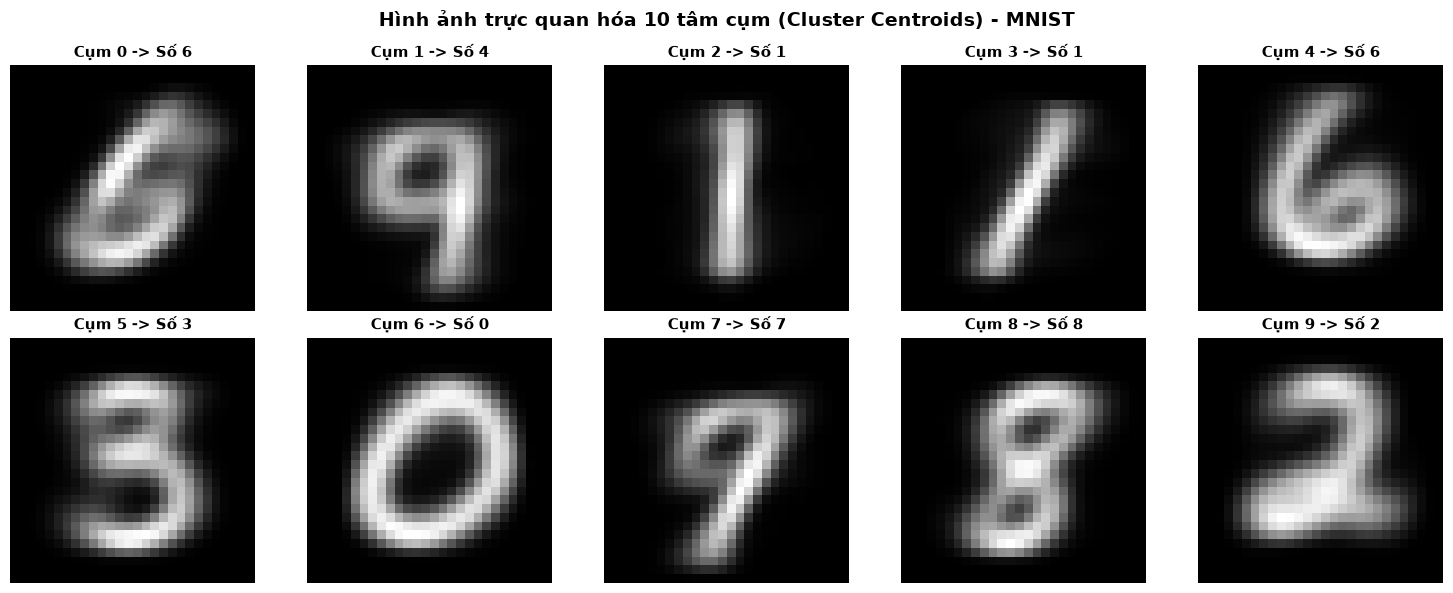

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

centroids = kmeans_mnist.cluster_centers_.reshape(10, 28, 28)

plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(centroids[i], cmap='gray')
    assigned_digit = cluster_to_digit[i]
    plt.title(f"Cụm {i} -> Số {assigned_digit}", fontsize=11, fontweight='bold')
    plt.axis('off')

plt.suptitle('Hình ảnh trực quan hóa 10 tâm cụm (Cluster Centroids) - MNIST', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()